=== Channel Asymmetry Summary ===
                    Channel  Labor_Volume_Pct  Economic_Return_Pct
      Agency (Intermediary)              78.8                 62.4
       Direct & Semi-Direct              15.2                 37.6
Social Capital / Networking               6.1                  0.0

=== Burnout Volatility Summary ===
                                            Tier  Events_Share_Pct  Income_Share_Pct
     Unpaid / Cancelled\n(Friction & Networking)              12.1               0.0
Baseline Residencies\n(High Frequency / Low Fee)              33.3              12.5
            Mid-Tier Events\n(Standard Bookings)              30.3              23.4
           Peak Seasonal Spikes\n(24% of Events)              24.2              64.1


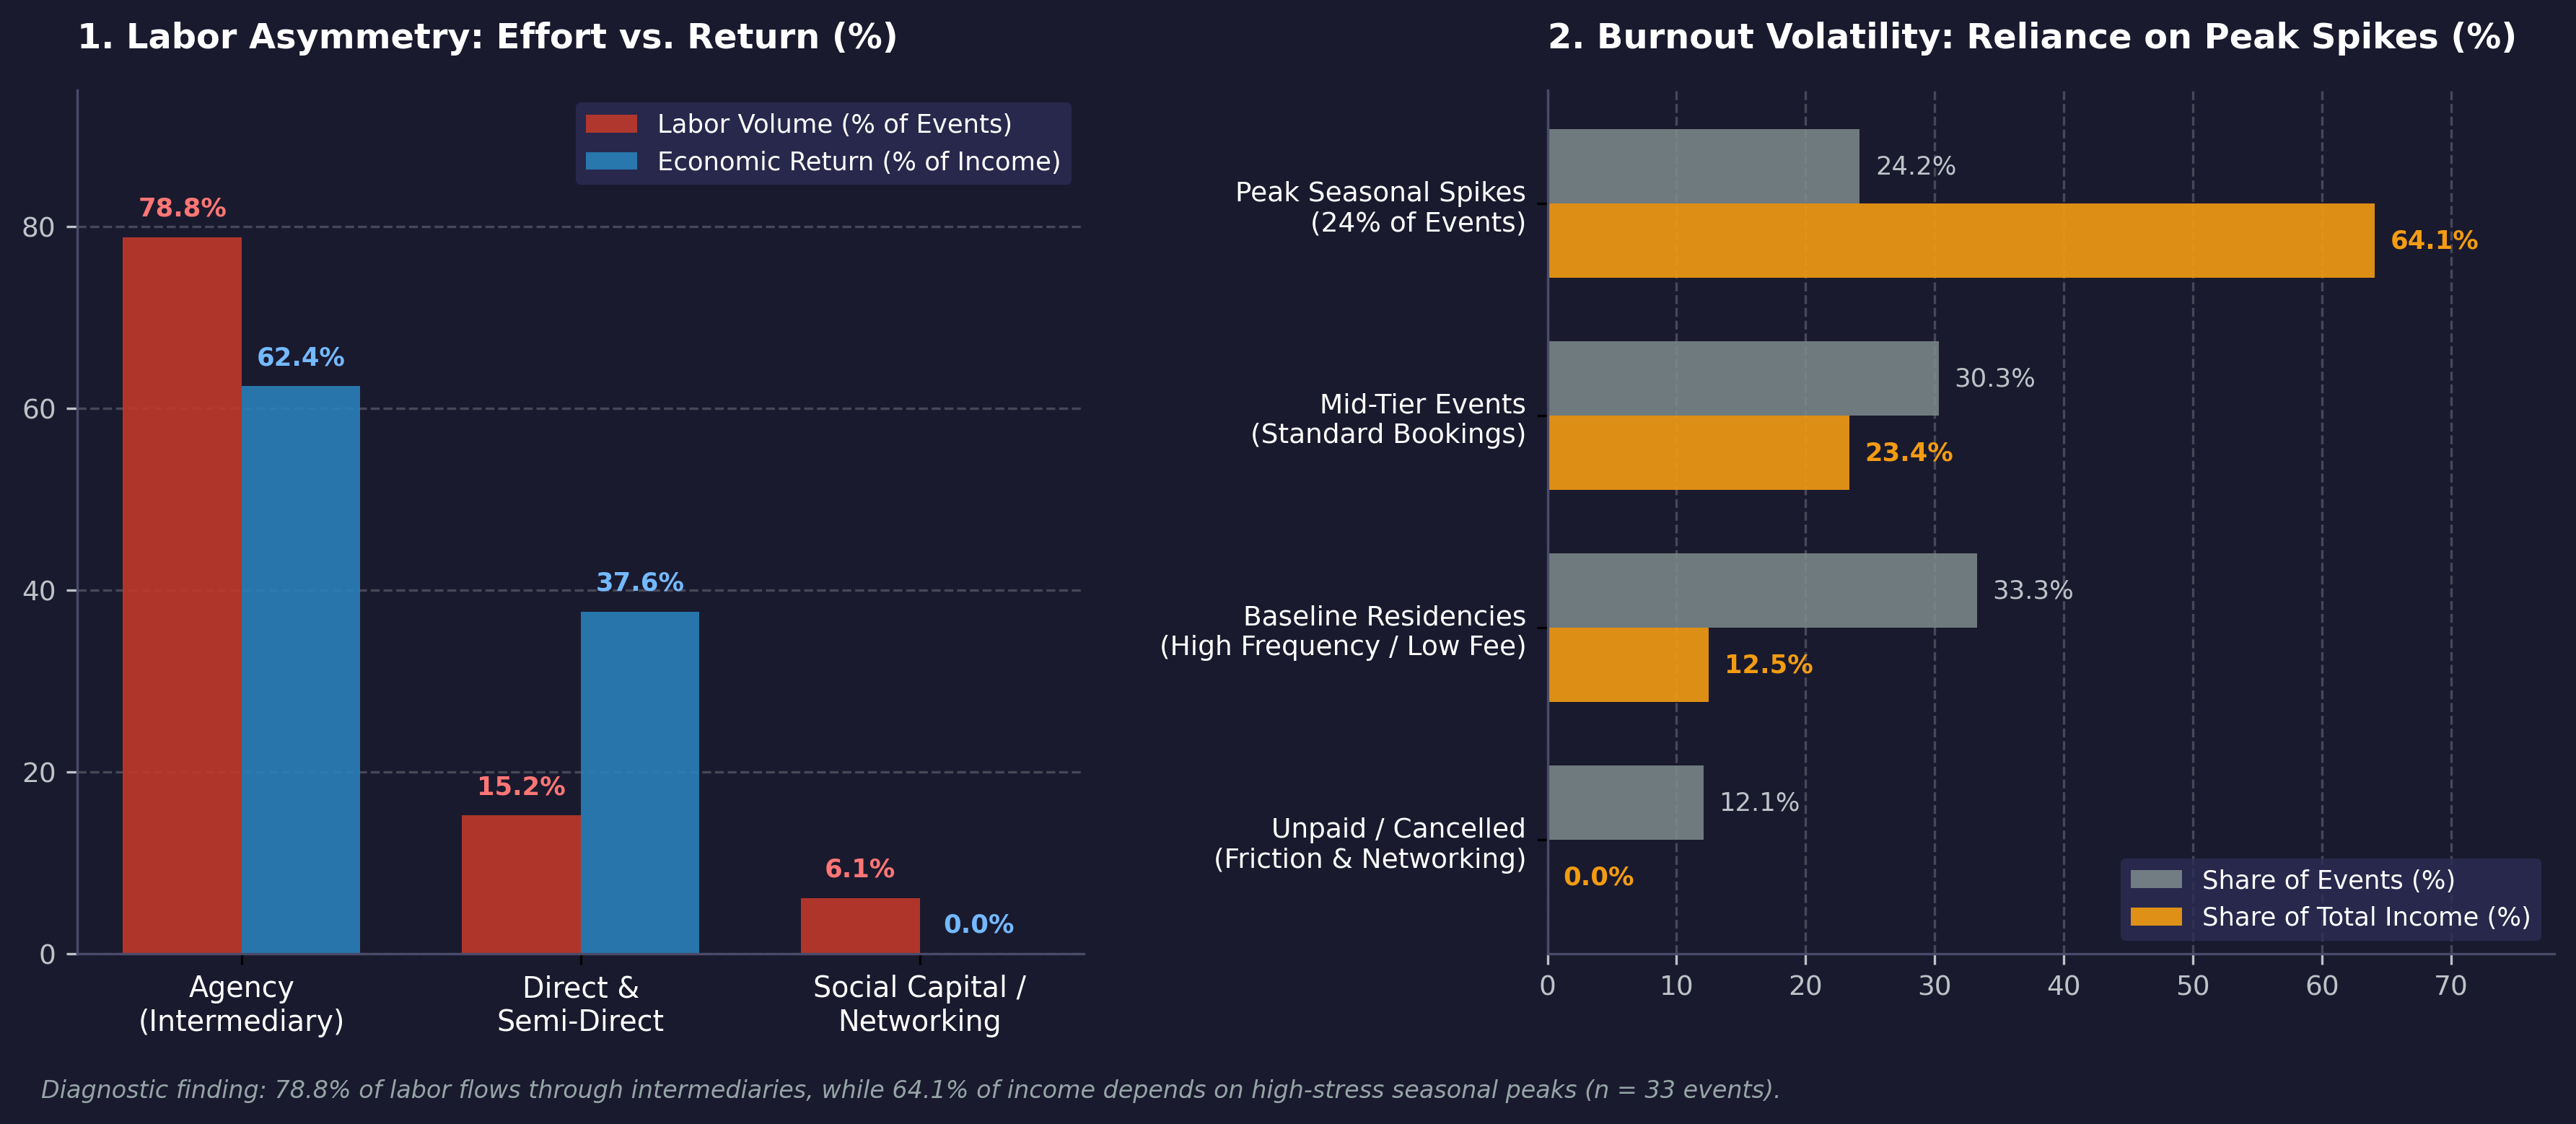

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Normalized Channel Taxonomy Dataset (Anonymized %, n = 33 records)
channel_data = pd.DataFrame({
    'Channel': ['Agency (Intermediary)', 'Direct & Semi-Direct', 'Social Capital / Networking'],
    'Labor_Volume_Pct': [78.8, 15.2, 6.1],
    'Economic_Return_Pct': [62.4, 37.6, 0.0]
})

# 2. Normalized Operational Tier Dataset (Anonymized %)
tier_data = pd.DataFrame({
    'Tier': [
        'Unpaid / Cancelled\n(Friction & Networking)',
        'Baseline Residencies\n(High Frequency / Low Fee)',
        'Mid-Tier Events\n(Standard Bookings)',
        'Peak Seasonal Spikes\n(24% of Events)'
    ],
    'Events_Share_Pct': [12.1, 33.3, 30.3, 24.2],
    'Income_Share_Pct': [0.0, 12.5, 23.4, 64.1]
})

print("=== Channel Asymmetry Summary ===")
print(channel_data.to_string(index=False))
print("\n=== Burnout Volatility Summary ===")
print(tier_data.to_string(index=False))

# 3. Generate Comparative Dark-Theme Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2), dpi=300)
fig.patch.set_facecolor('#1a1a2e')

# Panel 1: Effort vs. Return
x = np.arange(len(channel_data))
width = 0.35

ax1.set_facecolor('#1a1a2e')
rects1 = ax1.bar(x - width/2, channel_data['Labor_Volume_Pct'], width, label='Labor Volume (% of Events)', color='#c0392b', alpha=0.9)
rects2 = ax1.bar(x + width/2, channel_data['Economic_Return_Pct'], width, label='Economic Return (% of Income)', color='#2980b9', alpha=0.9)

ax1.set_title('1. Labor Asymmetry: Effort vs. Return (%)', color='white', fontsize=11.5, fontweight='bold', loc='left', pad=14)
ax1.set_xticks(x)
ax1.set_xticklabels(['Agency\n(Intermediary)', 'Direct &\nSemi-Direct', 'Social Capital /\nNetworking'], color='white', fontsize=9.5)
ax1.set_ylim(0, 95)
ax1.tick_params(axis='y', colors='#bdc3c7', labelsize=9)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['bottom'].set_color('#4a4a6a')
ax1.spines['left'].set_color('#4a4a6a')
ax1.yaxis.grid(True, linestyle='--', alpha=0.2, color='white')
ax1.set_axisbelow(True)
ax1.legend(facecolor='#2c2c54', edgecolor='none', labelcolor='white', fontsize=8.5, loc='upper right')

for rect in rects1:
    h = rect.get_height()
    ax1.text(rect.get_x() + rect.get_width()/2., h + 1.8, f'{h:.1f}%', ha='center', va='bottom', color='#ff7675', fontsize=8.5, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    ax1.text(rect.get_x() + rect.get_width()/2., h + 1.8, f'{h:.1f}%', ha='center', va='bottom', color='#74b9ff', fontsize=8.5, fontweight='bold')

# Panel 2: Burnout Volatility
y = np.arange(len(tier_data))
height = 0.35

ax2.set_facecolor('#1a1a2e')
b1 = ax2.barh(y + height/2, tier_data['Events_Share_Pct'], height, label='Share of Events (%)', color='#7f8c8d', alpha=0.85)
b2 = ax2.barh(y - height/2, tier_data['Income_Share_Pct'], height, label='Share of Total Income (%)', color='#f39c12', alpha=0.9)

ax2.set_title('2. Burnout Volatility: Reliance on Peak Spikes (%)', color='white', fontsize=11.5, fontweight='bold', loc='left', pad=14)
ax2.set_yticks(y)
ax2.set_yticklabels(tier_data['Tier'], color='white', fontsize=9)
ax2.set_xlim(0, 78)
ax2.tick_params(axis='x', colors='#bdc3c7', labelsize=9)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['bottom'].set_color('#4a4a6a')
ax2.spines['left'].set_color('#4a4a6a')
ax2.xaxis.grid(True, linestyle='--', alpha=0.2, color='white')
ax2.set_axisbelow(True)
ax2.legend(facecolor='#2c2c54', edgecolor='none', labelcolor='white', fontsize=8.5, loc='lower right')

for bar in b1:
    w = bar.get_width()
    ax2.text(w + 1.2, bar.get_y() + bar.get_height()/2., f'{w:.1f}%', va='center', ha='left', color='#bdc3c7', fontsize=8.5)
for bar in b2:
    w = bar.get_width()
    ax2.text(w + 1.2, bar.get_y() + bar.get_height()/2., f'{w:.1f}%', va='center', ha='left', color='#f39c12', fontsize=8.5, fontweight='bold')

fig.text(0.02, 0.015, 'Diagnostic finding: 78.8% of labor flows through intermediaries, while 64.1% of income depends on high-stress seasonal peaks (n = 33 events).', color='#95a5a6', fontsize=8, style='italic')

plt.tight_layout(rect=[0, 0.04, 1, 1], w_pad=2.5)
plt.savefig('unsustainable_creative_labor.png', facecolor='#1a1a2e', dpi=300)
plt.show()
